In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df = pd.read_csv("temperature_electricity_polynomial_regression.csv")
print(df.shape)
df.head()

(240, 2)


,temperature_c,daily_electricity_kwh
0,41.56,183.76
1,40.72,162.43
2,9.15,93.17
3,23.07,56.74
4,21.03,55.71


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   temperature_c          240 non-null    float64
 1   daily_electricity_kwh  240 non-null    float64
dtypes: float64(2)
memory usage: 3.9 KB


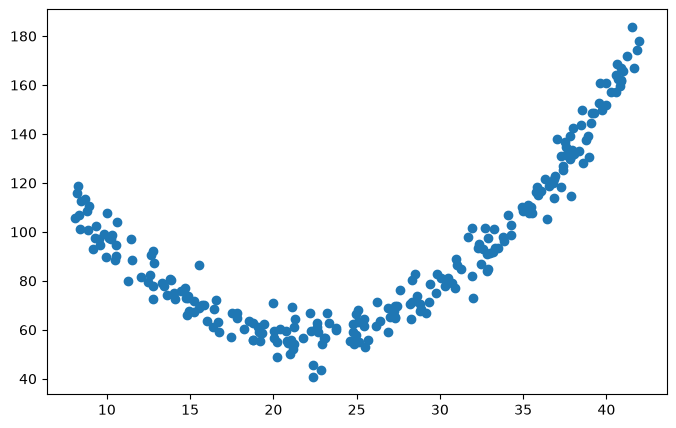

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df["temperature_c"], df["daily_electricity_kwh"])

In [6]:
X = df[["temperature_c"]]
y = df["daily_electricity_kwh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 192 | Test size: 48


In [7]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

y_pred = lin_model.predict(X_test)
print("Linear regression")
print("  R2 score :", round(r2_score(y_test, y_pred), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

Linear regression
  R2 score : 0.328
  RMSE     : 26.184


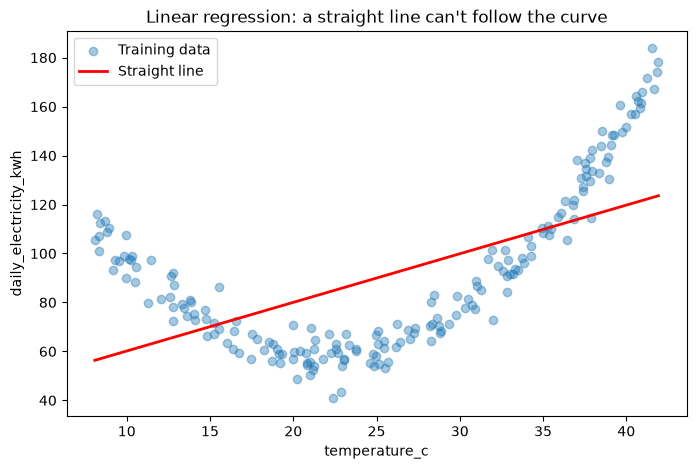

In [8]:
# A smooth range of horsepower values, used only for drawing lines/curves
x_range = pd.DataFrame({"temperature_c": np.linspace(X["temperature_c"].min(), X["temperature_c"].max(), 300)})

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.4, label="Training data")
plt.plot(x_range, lin_model.predict(x_range), color="red", linewidth=2, label="Straight line")
plt.xlabel("temperature_c")
plt.ylabel("daily_electricity_kwh")
plt.title("Linear regression: a straight line can't follow the curve")
plt.legend()
plt.show()

In [9]:
sample = X_train.head(3)

poly = PolynomialFeatures(degree=3, include_bias=False)
sample_poly = poly.fit_transform(sample)
print(sample_poly.shape)

pd.DataFrame(sample_poly, columns=poly.get_feature_names_out(), index=sample.index)

(3, 3)


,temperature_c,temperature_c^2,temperature_c^3
139,28.88,834.0544,24087.491072
60,40.97,1678.5409,68769.820673
204,33.87,1147.1769,38854.881603


In [15]:
def make_poly_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linreg", LinearRegression()),
    ])

# Try degree 2
poly2 = make_poly_model(2)
poly2.fit(X_train, y_train)

y_pred2 = poly2.predict(X_test)
print("Polynomial regression (degree 2)")
print("  R2 score :", round(r2_score(y_test, y_pred2), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred2)), 3))

Polynomial regression (degree 2)
  R2 score : 0.973
  RMSE     : 5.214


In [11]:
pipeline = make_poly_model(degree=1)   # the degree here will be overridden by the grid

param_grid = {
    "poly__degree": list(range(1, 11))   # "poly" is the step name, "degree" is its parameter
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",   # scikit-learn maximises scores, so error is made negative
)

grid.fit(X_train, y_train)

print("Best degree :", grid.best_params_["poly__degree"])
print("Best CV RMSE:", round(-grid.best_score_, 3))

Best degree : 3
Best CV RMSE: 6.062


In [16]:
best_model = grid.best_estimator_   # already refitted on the full training set

y_pred_best = best_model.predict(X_test)
print(f"Best model (degree {best_d}) on the test set")
print("  R2 score :", round(r2_score(y_test, y_pred_best), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 3))

NameError: name 'best_d' is not defined